# GCN_DS2_POS · GCN on Retail POS (Dataset 2, shared monthly customer–category graphs)

**Owner:** Hansen · **Dataset:** Retail POS · **Input:** the frozen Run 2 snapshots in `graph_data/v3/retail_pos`

It also reads the team contract `results/v3/run0/project_contract_v3.json`, the shared baseline scores `results/v4/run3_baselines/exhaustive/tables/run3_metrics.csv.gz` and, for Section 13, the processed transactions in `data/v3/processed/` (all paths relative to the repository root).

This notebook follows the team's **final standard**:

| Item | Final standard | This notebook |
|---|---|---|
| Data and time split | Retail POS monthly: 8 train, 2 validation, 2 test months (EuroMart: quarterly) | Retail POS, Run 2 monthly snapshots |
| What is predicted | customer → 17 categories, all 17 scored | same |
| Graph, labels, features | the exact Run 2 snapshots (7 customer + 7 category features) | loaded with `load_snapshot_v3.py`, nothing rebuilt |
| Loss | full BCE over the 17 candidates with the shared `pos_weight` | same |
| Model selection | validation **NDCG@10** for checkpoints and settings | same |
| Seeds | 42, 43, 44 | same |
| Reported | Recall / Precision / NDCG / HitRate @3, @5, @10 + PR-AUC; headline NDCG@5 | same |
| Decoder | dot product | same |

The EuroMart (Dataset 1) GCN is Yi Xuan's notebook `GCN_DS1_EuroMart.ipynb`.

**Question:** does graph convolution add predictive value beyond the same model without message passing (0 layers), and how sensitive is it to the number of layers?

**Reading route:** 1 setup → 2 data → 3 graph → 4 model → 5 metrics and simple baselines → 6 training → 7 layers → 8 small tuning (Figure 1) → 9 final seeds + test → 10 test results (Figure 2) → 11 ablation and over-smoothing (Figure 3) → 12 success vs failure (Figure 4) → 13 comparison with EuroMart (Figure 5) → 14 precision–recall curves (Figure 6) → 15 save → 16 conclusions. Runs in under a minute on one CPU thread.

## 1. Setup

In [1]:
import json, time, random, importlib.util, hashlib, platform, subprocess
from datetime import datetime, timezone
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display

torch.set_num_threads(1)                      # one thread + fixed seeds = the same numbers on every run
torch.use_deterministic_algorithms(True)

ROOT = Path.cwd()
DATASET = "retail_pos"
GRAPH_DIR = ROOT / "graph_data" / "v3"
OUT = ROOT / "results" / "v4" / "run4_gcn"          # v4 = the team's final standard (selection on validation NDCG@10)
FIG = OUT / "figures"
for folder in [OUT / "tables", OUT / "predictions", FIG]:
    folder.mkdir(parents=True, exist_ok=True)

CONTRACT = json.loads((ROOT / "results/v3/run0/project_contract_v3.json").read_text())
N_CAT, KS, SEEDS = 17, [3, 5, 10], [42, 43, 44]
SELECT = "NDCG@10"      # final standard: checkpoints and settings are chosen on validation NDCG@10
HEADLINE = "NDCG@5"     # headline metric in the tables
POS_WEIGHT = json.loads((GRAPH_DIR / DATASET / "loss_diagnostics.json").read_text())["primary_scalar_pos_weight"]
print("PyTorch", torch.__version__, "| seeds", SEEDS, "| selection metric", SELECT, "| pos_weight", round(POS_WEIGHT, 3))

PyTorch 2.14.0+cpu | seeds [42, 43, 44] | selection metric NDCG@10 | pos_weight 2.534


`pos_weight` = (non-purchased pairs) / (purchased pairs) over all training candidate pairs, computed once by Run 2: about 1 in 3.5 customer–category pairs is a purchase. Every model in the comparison uses the same value.

## 2. Load the shared Run 2 snapshots

One snapshot per target month *m*:
- **graph**: every customer–category purchase strictly before *m* (customers = nodes `0..487`, the 17 categories are nodes `488..504`);
- **features**: 7 customer and 7 category features, z-scored with training-history statistics;
- **labels**: for each *eligible* customer (seen before and active in *m*), which of the 17 categories they buy in *m*.

We use the team loader `graph_data/v3/load_snapshot_v3.py` with its hash check and do **not** rebuild graphs or labels. The test months are loaded only after all settings are frozen (Section 9).

In [2]:
spec = importlib.util.spec_from_file_location("load_snapshot_v3", GRAPH_DIR / "load_snapshot_v3.py")
loader = importlib.util.module_from_spec(spec)
spec.loader.exec_module(loader)
META = loader.load_dataset_metadata(ROOT, DATASET)
INDEX, CATEGORIES = META["snapshot_index"], META["categories"]["category"].tolist()


def load_split(split):
    rows = INDEX[INDEX["split"].eq(split) & INDEX["usable_for_supervision"].astype(bool)]
    snaps = []
    for month in rows["target_month"].astype(str):
        a, _ = loader.load_snapshot(ROOT, DATASET, month, verify_hash=True)
        snaps.append({
            "month": month,
            "cu": torch.tensor(a["customer_features"]),              # [all customers, 7]
            "ca": torch.tensor(a["category_features"]),               # [17, 7]
            "edge_index": torch.tensor(a["edge_index"]),              # both directions, no self-loops
            "eligible": torch.tensor(a["eligible_customer_idx"]),     # customers scored this month
            "labels": torch.tensor(a["labels"], dtype=torch.float32), # [eligible, 17]
            "history_degree": a["eligible_history_degree"],           # categories bought before m
            "history_pair": a["eligible_history_pair_mask"].astype(bool),
            "popularity": a["category_features_raw"][:, 5],           # popularity share (baseline check)
        })
    return snaps


# Check the agreed split before any fitting. January has no prior history.
expected_months = {"train": [f"2024-{m:02d}" for m in range(1, 9)],
                   "val": ["2024-09", "2024-10"], "test": ["2024-11", "2024-12"]}
for split, months in expected_months.items():
    assert INDEX.loc[INDEX["split"].eq(split), "target_month"].astype(str).tolist() == months
assert len(CATEGORIES) == N_CAT
DATA = {split: load_split(split) for split in ["train", "val"]}
for snaps in DATA.values():
    for snap in snaps:
        assert snap["cu"].shape[1] == snap["ca"].shape[1] == 7
        assert snap["labels"].shape == (len(snap["eligible"]), N_CAT)
        assert torch.all(snap["labels"].sum(dim=1) > 0)
rows = []
for split, snaps in DATA.items():
    labels = torch.cat([s["labels"] for s in snaps])
    rows.append({"split": split, "target months": f"{snaps[0]['month']} to {snaps[-1]['month']}",
                 "months": len(snaps), "customer-months": len(labels), "positive pairs": int(labels.sum()),
                 "positive rate": round(float(labels.mean()), 3), "nodes": len(snaps[-1]["cu"]) + N_CAT,
                 "links in last graph": snaps[-1]["edge_index"].shape[1] // 2})
pd.DataFrame(rows)

,split,target months,months,customer-months,positive pairs,positive rate,nodes,links in last graph
0,train,2024-02 to 2024-08,7,680,3271,0.283,505,3596
1,val,2024-09 to 2024-10,2,255,1245,0.287,505,4261


**Result:** 7 training months (February–August 2024; January has no earlier history, so it only serves as history) and 2 validation months (September–October). Together with the 2 test months (November–December, still unseen) this is the 8 / 2 / 2 monthly split of the final standard. About 28–29% of all customer–category pairs are purchases, so a customer buys from roughly 5 of the 17 categories in a month. The graph has 505 nodes (488 customers + 17 categories) and grows to 4,261 purchase links by October.

## 3. The GCN graph: self-loops and normalisation

GCN (Kipf & Welling, 2017) adds a self-loop to every node and scales each edge by the degrees of its two ends:

$$\hat A=\tilde D^{-1/2}(A+I)\tilde D^{-1/2},\qquad \hat A_{ij}=\frac{1}{\sqrt{\tilde d_i\,\tilde d_j}}$$

- `A` is binary: 1 if the customer bought from the category before month *m* (the contract's primary connectivity).
- `I` keeps each node's own information; `d̃` = number of neighbours + 1.
- A category bought by many customers sends a smaller message to each of them than a niche category does.

The lecture writes the **row-normalised** matrix `A' = D̃⁻¹(A+I)` (a plain average of the node and its neighbours). We use the symmetric version and test the row version in Section 8.

In [3]:
def gcn_edges(edge_index, n_nodes, norm="sym"):
    """Normalised adjacency with self-loops as (source, target, weight) lists."""
    loops = torch.arange(n_nodes).repeat(2, 1)
    src, dst = torch.cat([edge_index, loops], dim=1)
    degree = torch.zeros(n_nodes).index_add_(0, dst, torch.ones(len(dst)))      # neighbours + 1
    weight = degree[src].rsqrt() * degree[dst].rsqrt() if norm == "sym" else 1.0 / degree[dst]
    return src, dst, weight


def add_gcn_edges(snaps):
    for s in snaps:
        s["edges"] = {norm: gcn_edges(s["edge_index"], len(s["cu"]) + N_CAT, norm) for norm in ["sym", "row"]}


def propagate(h, edges):
    """Return A_hat @ h: every node adds up its neighbours' (and its own) vectors times the edge weight."""
    src, dst, weight = edges
    return torch.zeros_like(h).index_add_(0, dst, h[src] * weight[:, None])


for snaps in DATA.values():
    add_gcn_edges(snaps)

s = DATA["val"][-1]
n = len(s["cu"]) + N_CAT
dense = {norm: torch.zeros(n, n).index_put_((s["edges"][norm][1], s["edges"][norm][0]), s["edges"][norm][2])
         for norm in ["sym", "row"]}
print(f"{s['month']}: {n} nodes, {s['edge_index'].shape[1] // 2} purchase links, "
      f"{len(s['edges']['sym'][2])} non-zero entries in A_hat (both directions + self-loops)")
print("Symmetric version is symmetric:", torch.allclose(dense["sym"], dense["sym"].T))
print("Row version rows sum to 1:", torch.allclose(dense["row"].sum(dim=1), torch.ones(n)))

2024-10: 505 nodes, 4261 purchase links, 9027 non-zero entries in A_hat (both directions + self-loops)
Symmetric version is symmetric: True
Row version rows sum to 1: True


## 4. The GCN model

1. **Input projection**: customers and categories have different features, so each type gets its own `Linear(7 → 64)` followed by ReLU.
2. **GCN layers:** $H \leftarrow \mathrm{ReLU}(\hat A H W + b)$. After one layer a customer has mixed in the categories it bought; after two layers also the customers who bought those categories (customer → category → customer).
3. **Decoder:** score each eligible customer against all 17 categories with a dot product $s(u,c)=z_u^\top z_c$ (lecture recommender slide).

ReLU follows every layer. Two switches give the ablations: with `num_layers=0` the model keeps the input projections and the decoder but skips message passing (**GCN-NoMessages**, "no graph"); with `use_ids=True` each node starts from a **learned ID vector** instead of its 7 features (**GCN-ID**, "no node features").

In [4]:
class GCN(nn.Module):
    def __init__(self, cfg, n_customers):
        super().__init__()
        self.cfg = dict(cfg)
        hidden, layers = cfg["hidden_dim"], cfg["num_layers"]
        if cfg["use_ids"]:
            self.customer_input = nn.Embedding(n_customers, hidden)
            self.category_input = nn.Embedding(N_CAT, hidden)
            nn.init.normal_(self.customer_input.weight, std=0.1)
            nn.init.normal_(self.category_input.weight, std=0.1)
        else:
            self.customer_input = nn.Linear(7, hidden)
            self.category_input = nn.Linear(7, hidden)
        dims = [hidden] * layers + [cfg["embedding_dim"]]
        self.weights = nn.ModuleList([nn.Linear(dims[i], dims[i + 1], bias=False) for i in range(layers)])
        self.biases = nn.ParameterList([nn.Parameter(torch.zeros(dims[i + 1])) for i in range(layers)])

    def encode(self, s):
        if self.cfg["use_ids"]:
            h = torch.cat([self.customer_input.weight, self.category_input.weight])
        else:
            h = torch.cat([self.customer_input(s["cu"]), self.category_input(s["ca"])])
        h = F.relu(h)
        for W, b in zip(self.weights, self.biases):
            h = F.relu(propagate(W(h), s["edges"][self.cfg["norm"]]) + b)
            h = F.dropout(h, p=self.cfg["dropout"], training=self.training)
        return h

    def forward(self, s):
        z = self.encode(s)
        return z[s["eligible"]] @ z[len(s["cu"]):].T          # logits: [eligible customers, 17]


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


DEFAULT = {"num_layers": 2, "hidden_dim": 64, "embedding_dim": 64, "learning_rate": 1e-3,
           "weight_decay": 1e-5, "dropout": 0.0, "norm": "sym", "use_ids": False}
for layers in [0, 1, 2, 3]:
    print(f"GCN with {layers} layer(s): {count_parameters(GCN({**DEFAULT, 'num_layers': layers}, 1)):,} parameters")

GCN with 0 layer(s): 1,024 parameters
GCN with 1 layer(s): 5,184 parameters
GCN with 2 layer(s): 9,344 parameters
GCN with 3 layer(s): 13,504 parameters


`DEFAULT` is the shared starting point of the team contract (64-d, Adam, learning rate 0.001, weight decay 1e-5, no dropout). Each GCN layer adds 4,160 parameters (a 64 × 64 weight matrix and a bias).

## 5. Metrics and simple baselines

For each eligible customer-month we rank all 17 categories (stable sort: equal scores keep category order), then average over customer-months:
- **Recall@K** = categories bought that appear in the top K / categories bought
- **Precision@K** = hits in the top K / K
- **NDCG@K** = DCG / best possible DCG, with $DCG=\sum_r hit_r/\log_2(r+1)$, so hits near the top count more
- **HitRate@K** = 1 if at least one bought category is in the top K
- **PR-AUC** = average precision over all customer–category pairs of the split pooled together (numpy version of `sklearn.metrics.average_precision_score`).

**Simple baselines** (no learning) are the reference points: **GlobalPopularity** (the same most-bought categories for everyone), **PersonalHistory** and **RepeatLastMonth** (the customer's own earlier purchases) and **Random**, read from the team's shared baseline file (`results/v4/run3_baselines/exhaustive`). The check below recomputes GlobalPopularity on the validation months and compares all 13 metrics with that file.

In [5]:
METRICS = [f"{m}@{k}" for k in KS for m in ["Recall", "Precision", "NDCG", "HitRate"]] + ["PR-AUC"]


def per_customer_metrics(labels, scores):
    labels = np.asarray(labels, dtype=float)
    order = np.argsort(-np.asarray(scores, dtype=float), axis=1, kind="stable")
    ranked = np.take_along_axis(labels, order, axis=1)
    n_pos = labels.sum(axis=1)
    discounts = 1 / np.log2(np.arange(2, N_CAT + 2))
    out = {}
    for k in KS:
        hits = ranked[:, :k].sum(axis=1)
        ideal = np.array([discounts[:int(min(p, k))].sum() for p in n_pos])
        out[f"Recall@{k}"] = hits / n_pos
        out[f"Precision@{k}"] = hits / k
        out[f"NDCG@{k}"] = (ranked[:, :k] * discounts[:k]).sum(axis=1) / ideal
        out[f"HitRate@{k}"] = (hits > 0).astype(float)
    return out


def average_precision(labels, scores):
    y, s = np.ravel(labels).astype(float), np.ravel(scores).astype(float)
    order = np.argsort(-s, kind="mergesort")
    y, s = y[order], s[order]
    last_of_each_score = np.r_[np.flatnonzero(np.diff(s)), len(s) - 1]     # equal scores share one threshold
    true_pos = np.cumsum(y)[last_of_each_score]
    precision = true_pos / (last_of_each_score + 1)
    recall = true_pos / true_pos[-1]
    return float(np.sum(np.diff(np.r_[0.0, recall]) * precision))


def ranking_metrics(labels, scores):
    out = {name: float(values.mean()) for name, values in per_customer_metrics(labels, scores).items()}
    out["PR-AUC"] = average_precision(labels, scores)
    return {m: out[m] for m in METRICS}


def popularity_scores(s):
    """Run 3 GlobalPopularity: same ranking for everyone, most popular category first."""
    order = np.lexsort((np.arange(N_CAT), -s["popularity"]))
    row = np.empty(N_CAT)
    row[order] = np.arange(N_CAT, 0, -1)
    return np.tile(row, (len(s["labels"]), 1))


BASELINES = ["GlobalPopularity", "PersonalHistory", "RepeatLastMonth", "Random"]
def shared_baselines(splits):
    # Filter each chunk immediately; test scores are neither aggregated nor displayed during tuning.
    parts = []
    for chunk in pd.read_csv(ROOT / "results/v4/run3_baselines/exhaustive/tables/run3_metrics.csv.gz", chunksize=1000):
        keep = (chunk["dataset"].eq(DATASET) & chunk["seed"].isin(SEEDS)
                & chunk["method"].isin(BASELINES) & chunk["split"].isin(splits))
        parts.append(chunk.loc[keep])
    return pd.concat(parts).groupby(["method", "split"], sort=False)[METRICS].agg(["mean", "std"])

shared = shared_baselines(["val"])

val = DATA["val"]
mine = ranking_metrics(np.concatenate([s["labels"].numpy() for s in val]),
                       np.concatenate([popularity_scores(s) for s in val]))
largest_gap = max(abs(mine[m] - shared.loc[("GlobalPopularity", "val"), (m, "mean")]) for m in METRICS)
print(f"GlobalPopularity validation NDCG@10 {mine['NDCG@10']:.6f} (team file: "
      f"{shared.loc[('GlobalPopularity', 'val'), ('NDCG@10', 'mean')]:.6f}); largest difference over 13 metrics = {largest_gap:.1e}")
assert largest_gap < 1e-9
shared.xs("mean", axis=1, level=1)[[HEADLINE, SELECT, "Recall@10", "PR-AUC"]].round(4)

GlobalPopularity validation NDCG@10 0.623665 (team file: 0.623665); largest difference over 13 metrics = 1.1e-16


,,NDCG@5,NDCG@10,Recall@10,PR-AUC
method,split,,,,
Random,val,0.2997,0.4364,0.5875,0.2893
GlobalPopularity,val,0.4792,0.6237,0.7665,0.4112
PersonalHistory,val,0.4212,0.5702,0.7206,0.3709
RepeatLastMonth,val,0.4266,0.5710,0.7161,0.3733


**Result:** our metric code reproduces the team file exactly (largest difference 1e-16 over all 13 metrics). On validation, popularity already reaches NDCG@10 0.624 and a random ranking 0.436. With only 17 candidates, of which about 5 are bought, every sensible ranking is squeezed into a narrow band, so popularity is the bar the GCN has to clear.

## 6. Training

- One **epoch** = a forward pass on every training month. The loss is binary cross-entropy on the logits of **all** eligible customer × 17 category pairs with the shared `pos_weight`, summed and divided by the number of training pairs, then **one Adam step** per epoch.
- After each epoch: **validation NDCG@10** over both validation months together. Keep the best weights; stop after `patience` epochs without improvement.
- Budgets from the team contract: 100 epochs / patience 10 while choosing settings, 200 / 20 for the final seeds.

In [6]:
SEARCH_BUDGET = {"max_epochs": 100, "patience": 10}
FINAL_BUDGET = {"max_epochs": 200, "patience": 20}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


@torch.no_grad()
def predict(model, snaps):
    model.eval()
    return [model(s).numpy() for s in snaps]


def val_score(model, snaps):
    labels = np.concatenate([s["labels"].numpy() for s in snaps])
    return float(per_customer_metrics(labels, np.concatenate(predict(model, snaps)))[SELECT].mean())


def train_gcn(cfg, seed, budget):
    set_seed(seed)
    train, val = DATA["train"], DATA["val"]
    model = GCN(cfg, n_customers=len(train[0]["cu"]))
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["learning_rate"], weight_decay=cfg["weight_decay"])
    pos_weight = torch.tensor(POS_WEIGHT)
    n_pairs = sum(s["labels"].numel() for s in train)
    best, best_epoch, best_state, stale, history = -np.inf, 0, None, 0, []
    start = time.perf_counter()
    for epoch in range(1, budget["max_epochs"] + 1):
        model.train()
        optimizer.zero_grad()
        loss_sum = 0.0
        for s in train:
            loss = F.binary_cross_entropy_with_logits(model(s), s["labels"], pos_weight=pos_weight, reduction="sum")
            (loss / n_pairs).backward()
            loss_sum += loss.item()
        optimizer.step()
        score = val_score(model, val)
        history.append({"epoch": epoch, "train_loss": loss_sum / n_pairs, f"val_{SELECT}": score})
        if score > best + 1e-12:
            best, best_epoch, best_state, stale = score, epoch, deepcopy(model.state_dict()), 0
        else:
            stale += 1
            if stale >= budget["patience"]:
                break
    model.load_state_dict(best_state)
    info = {f"val_{SELECT}": best, "best_epoch": best_epoch, "epochs_run": epoch,
            "num_parameters": count_parameters(model), "training_seconds": time.perf_counter() - start}
    return model, pd.DataFrame(history), info

## 7. Number of layers: 0, 1, 2 or 3 (controlled track)

The team contract names the number of layers (1, 2, 3) as the GCN sensitivity parameter. Everything else stays at `DEFAULT`; seed 42 and the search budget; the depth with the best **validation NDCG@10** wins. **0 layers** (no message passing) is trained as a reference only: the gap between 0 and the best depth is what the graph adds.

In [7]:
SEARCH_SEED = 42
TRIALS = {}        # settings -> result, so the same setting is never trained twice


def trial(cfg, stage):
    key = json.dumps(cfg, sort_keys=True)
    if key not in TRIALS:
        model, history, info = train_gcn(cfg, SEARCH_SEED, SEARCH_BUDGET)
        TRIALS[key] = {"stage": stage, **cfg, **info, "model": model}
    return TRIALS[key]


depth_table = pd.DataFrame([{k: trial({**DEFAULT, "num_layers": layers}, "layers")[k]
                             for k in ["num_layers", f"val_{SELECT}", "best_epoch", "num_parameters"]}
                            for layers in [0, 1, 2, 3]])
with_graph = depth_table[depth_table["num_layers"] > 0]                 # 0 layers is only a reference
BEST_DEPTH = int(with_graph.sort_values(f"val_{SELECT}", ascending=False, kind="stable").iloc[0]["num_layers"])
print("Best number of layers on validation:", BEST_DEPTH)
depth_table.round(4)

Best number of layers on validation: 2


,num_layers,val_NDCG@10,best_epoch,num_parameters
0,0,0.6287,5,1024
1,1,0.6255,11,5184
2,2,0.6303,33,9344
3,3,0.6261,9,13504


**Result:** 2 layers is best on validation (NDCG@10 0.6303 vs 0.6255 for 1 layer and 0.6261 for 3 layers), so GCN-Controlled uses 2 layers. Without any message passing (0 layers) the same model already reaches 0.6287: the best depth adds only 0.0016, and 1 or 3 layers are even below no graph at all. These gaps are about the size of the differences between seeds (Section 9).

## 8. Small tuning, one setting at a time (GCN-Tuned) — Figure 1

The master plan asks for a *similarly small* tuning budget per model. Starting from the best depth we change **one setting at a time** and keep a new value only if validation NDCG@10 improves: hidden/embedding size 32 / 64 / 128, dropout 0 / 0.3 / 0.5, learning rate 0.0003 / 0.001 / 0.003, weight decay 0 / 1e-5 / 1e-4, normalisation symmetric vs row (lecture A'), and finally the depth again. Validation only, seed 42, search budget.

In [8]:
STAGES = {
    "hidden/embedding size": (["hidden_dim", "embedding_dim"], [32, 64, 128]),
    "dropout": (["dropout"], [0.0, 0.3, 0.5]),
    "learning rate": (["learning_rate"], [3e-4, 1e-3, 3e-3]),
    "weight decay": (["weight_decay"], [0.0, 1e-5, 1e-4]),
    "normalisation": (["norm"], ["sym", "row"]),
    "layers (re-check)": (["num_layers"], [1, 2, 3]),
}
current, sensitivity_rows = {**DEFAULT, "num_layers": BEST_DEPTH}, []
for stage, (keys, values) in STAGES.items():
    scores = {v: trial({**current, **{k: v for k in keys}}, stage)[f"val_{SELECT}"] for v in values}
    winner = max(values, key=lambda v: scores[v])           # first value with the best score
    if scores[winner] > scores[current[keys[0]]] + 1e-12:
        current = {**current, **{k: winner for k in keys}}
    sensitivity_rows += [{"parameter": stage, "value": v, f"val_{SELECT}": scores[v],
                          "kept": v == current[keys[0]]} for v in values]
TUNED = current
print("Tuned settings:", {k: v for k, v in TUNED.items() if v != DEFAULT.get(k)} or "same as DEFAULT")

layer_rows = depth_table.assign(parameter="layers", value=depth_table["num_layers"],
                                kept=depth_table["num_layers"].eq(BEST_DEPTH))
sensitivity = pd.concat([layer_rows[["parameter", "value", f"val_{SELECT}", "kept"]],
                         pd.DataFrame(sensitivity_rows)], ignore_index=True).astype({"value": str})
tuning_log = pd.DataFrame([{k: v for k, v in r.items() if k != "model"} for r in TRIALS.values()])
tuning_log.to_csv(OUT / "tables" / "gcn_tuning_log.csv", index=False)
print(len(tuning_log), "different settings trained")
sensitivity.set_index(["parameter", "value"]).round(4)

Tuned settings: {'weight_decay': 0.0001}
15 different settings trained


val_NDCG@10   kept
parameter             value                     
layers                0            0.6287  False
                      1            0.6255  False
                      2            0.6303   True
                      3            0.6261  False
hidden/embedding size 32           0.6264  False
                      64           0.6303   True
                      128          0.6303  False
dropout               0.0          0.6303   True
                      0.3          0.6284  False
                      0.5          0.6263  False
learning rate         0.0003       0.6266  False
                      0.001        0.6303   True
                      0.003        0.6289  False
weight decay          0.0          0.6303  False
                      1e-05        0.6303  False
                      0.0001       0.6325   True
normalisation         sym          0.6325   True
                      row          0.6235  False
layers (re-check)     1            0.6260  False
                      2            0.6325   True
                      3            0.6263  False

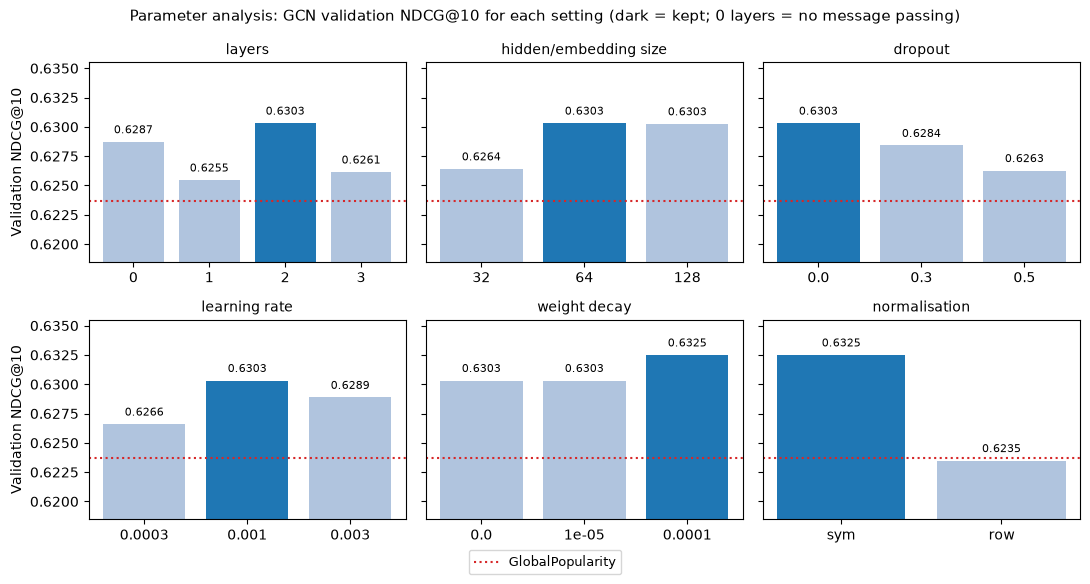

In [9]:
reference = {"GlobalPopularity": shared.loc[("GlobalPopularity", "val"), (SELECT, "mean")]}
PANELS = ["layers", "hidden/embedding size", "dropout", "learning rate", "weight decay", "normalisation"]
values = sensitivity[f"val_{SELECT}"]
low = min(values[values > values.max() - 0.05].min(), *reference.values()) - 0.005
high = max(values.max(), *reference.values()) + 0.003
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6), sharey=True)
for ax, parameter in zip(axes.flat, PANELS):
    rows = sensitivity[sensitivity["parameter"].eq(parameter)]
    bars = ax.bar(rows["value"], rows[f"val_{SELECT}"],
                  color=["tab:blue" if kept else "lightsteelblue" for kept in rows["kept"]])
    for bar, value in zip(bars, rows[f"val_{SELECT}"]):
        ax.text(bar.get_x() + bar.get_width() / 2, max(value, low) + 0.0005, f"{value:.4f}",
                ha="center", va="bottom", fontsize=8)
    ax.axhline(reference["GlobalPopularity"], color="tab:red", linestyle=":", linewidth=1.5, label="GlobalPopularity")
    ax.set_title(parameter, fontsize=10)
    ax.set_ylim(low, high)
for ax in axes[:, 0]:
    ax.set_ylabel(f"Validation {SELECT}")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=1, fontsize=9, bbox_to_anchor=(0.5, -0.04))
fig.suptitle(f"Parameter analysis: GCN validation {SELECT} for each setting (dark = kept; 0 layers = no message passing)", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "fig1_parameter_analysis.png", dpi=160, bbox_inches="tight")
plt.show()

**Result:** only one change was kept: weight decay 1e-4 (validation NDCG@10 0.6325, +0.002). Hidden size 128 ties with 64, dropout and the other learning rates are slightly worse (0.626–0.629), and the lecture's row normalisation is the worst setting tried (0.6235, just below popularity), probably because a plain average removes the degree signal that makes the symmetric GCN rank like popularity (Section 11). Re-checking the depth still picks 2 layers. Every setting lies within 0.009 of each other, so the GCN is not sensitive to its settings here. **GCN-Tuned = GCN-Controlled + weight decay 1e-4.**

## 9. Final runs: freeze the settings, train 3 seeds, then use the test months once

Four variants, all chosen on validation only:
- **GCN-Controlled**: `DEFAULT` + best depth.
- **GCN-Tuned**: the one-at-a-time winner from Section 8 (skipped if tuning kept every default).
- **GCN-ID**: the controlled settings, but learned ID vectors replace the 7 features ("no node features").
- **GCN-NoMessages**: `DEFAULT` with 0 layers ("no graph"): same features, decoder and training, no message passing.

The settings are saved to `configs_hansen.json` **before** the test months are loaded.

In [10]:
controlled = {**DEFAULT, "num_layers": BEST_DEPTH}
VARIANTS = {"GCN-Controlled": controlled, "GCN-Tuned": TUNED, "GCN-ID": {**controlled, "use_ids": True},
            "GCN-NoMessages": {**DEFAULT, "num_layers": 0}}
if TUNED == controlled:
    del VARIANTS["GCN-Tuned"]
(OUT / "configs_hansen.json").write_text(json.dumps({DATASET: VARIANTS}, indent=2))
pd.DataFrame([{"variant": v, **cfg} for v, cfg in VARIANTS.items()])

,variant,num_layers,hidden_dim,embedding_dim,learning_rate,weight_decay,dropout,norm,use_ids
0,GCN-Controlled,2,64,64,0.001,0.00001,0.0,sym,False
1,GCN-Tuned,2,64,64,0.001,0.00010,0.0,sym,False
2,GCN-ID,2,64,64,0.001,0.00001,0.0,sym,True
3,GCN-NoMessages,0,64,64,0.001,0.00001,0.0,sym,False


In [11]:
def instance_table(snaps, scores):
    """Per customer-month metrics (used for the history-quartile analysis)."""
    return pd.concat([pd.DataFrame({"target_month": s["month"], "customer_idx": s["eligible"].numpy(),
                                    "history_degree": s["history_degree"],
                                    **per_customer_metrics(s["labels"].numpy(), sc)})
                      for s, sc in zip(snaps, scores)], ignore_index=True)


def prediction_table(snaps, scores):
    """One row per customer-month-category: score, true label and whether it was bought before."""
    return pd.concat([pd.DataFrame({"target_month": s["month"],
                                    "customer_idx": np.repeat(s["eligible"].numpy(), N_CAT),
                                    "category_idx": np.tile(np.arange(N_CAT), len(sc)),
                                    "score": sc.ravel(), "label": s["labels"].numpy().ravel().astype(int),
                                    "bought_before": s["history_pair"].ravel().astype(int)})
                      for s, sc in zip(snaps, scores)], ignore_index=True)


# Finish all final training and select the reporting variant before opening test snapshots.
result_rows, histories, test_scores, fitted = [], [], {}, {}
for variant, cfg in VARIANTS.items():
    for seed in SEEDS:
        model, history, info = train_gcn(cfg, seed, FINAL_BUDGET)
        fitted[variant, seed] = (model, info)
        histories.append(history.assign(variant=variant, seed=seed))
        for split in ["train", "val"]:
            snaps = DATA[split]
            result_rows.append({"variant": variant, "seed": seed, "split": split,
                                **ranking_metrics(np.concatenate([s["labels"].numpy() for s in snaps]),
                                                  np.concatenate(predict(model, snaps))),
                                **{k: info[k] for k in ["best_epoch", "num_parameters", "training_seconds"]}})
        print(f"{variant:15s} seed {seed}: best epoch {info['best_epoch']:3d}, "
              f"val {SELECT} {info[f'val_{SELECT}']:.4f}, {info['training_seconds']:.1f}s")
results = pd.DataFrame(result_rows)
val_mean = results[results["split"].eq("val")].groupby("variant")[SELECT].mean()
MAIN = val_mean.drop(["GCN-ID", "GCN-NoMessages"]).idxmax()
print("Reporting variant selected on validation:", MAIN)

DATA["test"] = load_split("test")
add_gcn_edges(DATA["test"])
shared = shared_baselines(["train", "val", "test"])
for (variant, seed), (model, info) in fitted.items():
    snaps = DATA["test"]
    scores = predict(model, snaps)
    test_scores[variant, seed] = scores
    result_rows.append({"variant": variant, "seed": seed, "split": "test",
                        **ranking_metrics(np.concatenate([s["labels"].numpy() for s in snaps]), np.concatenate(scores)),
                        **{k: info[k] for k in ["best_epoch", "num_parameters", "training_seconds"]}})
results = pd.DataFrame(result_rows)


GCN-Controlled  seed 42: best epoch  33, val NDCG@10 0.6303, 1.4s


GCN-Controlled  seed 43: best epoch   9, val NDCG@10 0.6334, 0.8s


GCN-Controlled  seed 44: best epoch  64, val NDCG@10 0.6303, 2.5s


GCN-Tuned       seed 42: best epoch  20, val NDCG@10 0.6325, 1.1s


GCN-Tuned       seed 43: best epoch  20, val NDCG@10 0.6359, 1.1s


...

GCN-ID          seed 43: best epoch   2, val NDCG@10 0.6282, 0.6s


GCN-ID          seed 44: best epoch   8, val NDCG@10 0.6289, 0.8s
GCN-NoMessages  seed 42: best epoch   5, val NDCG@10 0.6287, 0.1s


GCN-NoMessages  seed 43: best epoch   1, val NDCG@10 0.6217, 0.1s


GCN-NoMessages  seed 44: best epoch  60, val NDCG@10 0.6282, 0.5s


Reporting variant selected on validation: GCN-Tuned


## 10. Test results vs simple baselines — Figure 2

GCN rows are the mean of seeds 42 / 43 / 44; the simple baselines have no learning (Random: one run). **Difference from no messages** = NDCG@5 minus GCN-NoMessages' NDCG@5. Controlled vs NoMessages compares the default GCN stack with the zero-layer reference; removing the stack also removes its trainable transforms. Tuned additionally changes weight decay, and ID changes inputs, so those differences do not isolate message passing.

In [12]:
def method_summary(split):
    gcn = results[results["split"].eq(split)].groupby("variant", sort=False)[METRICS].agg(["mean", "std"])
    base = shared.xs(split, level="split")
    table = pd.concat([gcn, base])
    table.columns = [f"{m} {'sd' if a == 'std' else 'mean'}" for m, a in table.columns]
    return table


test_table = method_summary("test")
test_table["difference vs NoMessages (NDCG@5)"] = test_table["NDCG@5 mean"] - test_table.loc["GCN-NoMessages", "NDCG@5 mean"]
test_table = test_table.sort_values("NDCG@5 mean", ascending=False)
test_table[["NDCG@5 mean", "NDCG@5 sd", "NDCG@10 mean", "NDCG@10 sd", "Recall@10 mean", "HitRate@5 mean",
            "PR-AUC mean", "difference vs NoMessages (NDCG@5)"]].round(4)

,NDCG@5 mean,NDCG@5 sd,NDCG@10 mean,NDCG@10 sd,Recall@10 mean,HitRate@5 mean,PR-AUC mean,difference vs NoMessages (NDCG@5)
GCN-ID,0.4915,0.0011,0.6269,0.0011,0.7626,0.9580,0.3770,0.0044
GCN-Tuned,0.4877,0.0086,0.6262,0.0058,0.7683,0.9517,0.3831,0.0007
GlobalPopularity,0.4873,NaN,0.6291,NaN,0.7683,0.9427,0.4148,0.0002
GCN-NoMessages,0.4870,0.0013,0.6274,0.0025,0.7653,0.9466,0.3884,0.0000
GCN-Controlled,0.4851,0.0066,0.6246,0.0031,0.7664,0.9453,0.3863,-0.0019
PersonalHistory,0.4285,NaN,0.5713,NaN,0.7225,0.9084,0.3679,-0.0585
RepeatLastMonth,0.4225,NaN,0.5678,NaN,0.7221,0.9084,0.3632,-0.0645
Random,0.2925,NaN,0.4300,NaN,0.5844,0.8130,0.2765,-0.1946


In [13]:
stats = results[results["split"].eq("test")].groupby("variant", sort=False)
table = stats[["NDCG@5", "NDCG@10", "Recall@10", "PR-AUC", "best_epoch"]].mean()
table["parameters"] = stats["num_parameters"].first()
table["training seconds (per seed)"] = stats["training_seconds"].mean()
table.round(4)

,NDCG@5,NDCG@10,Recall@10,PR-AUC,best_epoch,parameters,training seconds (per seed)
variant,,,,,,,
GCN-Controlled,0.4851,0.6246,0.7664,0.3863,35.3333,9344,1.5559
GCN-Tuned,0.4877,0.6262,0.7683,0.3831,32.3333,9344,1.4763
GCN-ID,0.4915,0.6269,0.7626,0.3770,6.0000,40640,0.7302
GCN-NoMessages,0.4870,0.6274,0.7653,0.3884,22.0000,1024,0.2296


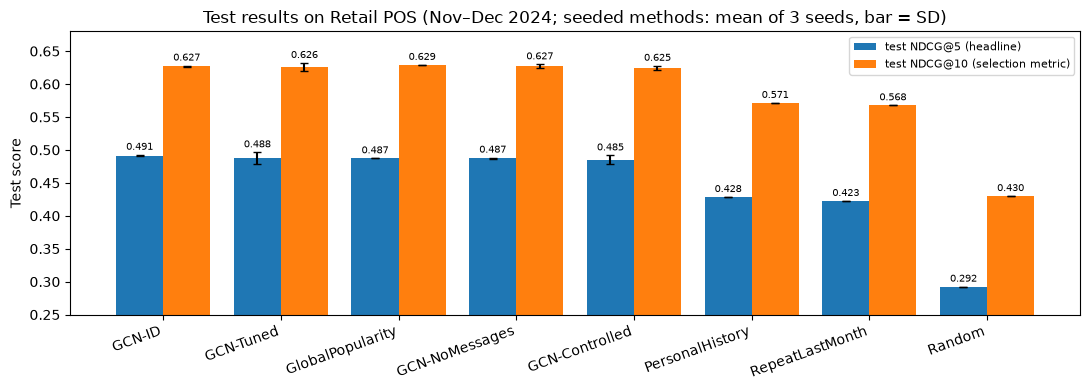

In [14]:
order = test_table.index.tolist()
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(11, 4))
for offset, metric, color in [(-0.2, "NDCG@5", "tab:blue"), (0.2, "NDCG@10", "tab:orange")]:
    means, sds = test_table[f"{metric} mean"], test_table[f"{metric} sd"].fillna(0)
    bars = ax.bar(x + offset, means, width=0.4, yerr=sds, capsize=3,
                  color=color, label=f"test {metric}" + (" (headline)" if metric == HEADLINE else " (selection metric)"))
    for bar, value, sd in zip(bars, means, sds):
        ax.text(bar.get_x() + bar.get_width() / 2, value + sd + 0.004, f"{value:.3f}", ha="center", va="bottom", fontsize=7)
ax.set_xticks(x, order, rotation=20, ha="right")
ax.set_ylim(0.25, 0.68)
ax.set_ylabel("Test score")
ax.legend(fontsize=8, loc="upper right")
ax.set_title("Test results on Retail POS (Nov–Dec 2024; seeded methods: mean of 3 seeds, bar = SD)")
plt.tight_layout()
plt.savefig(FIG / "fig2_test_results.png", dpi=160, bbox_inches="tight")
plt.show()

**Result:** GCN-Tuned scores test NDCG@5 **0.4877 ± 0.0086** and NDCG@10 **0.6262 ± 0.0058** (sample SD over three seeds), compared with 0.4870 / 0.6274 for GCN-NoMessages and 0.4873 / 0.6291 for popularity. Controlled is lower (0.4851 / 0.6246), while GCN-ID has the highest NDCG@5 (0.4915) and peaks after 2–8 epochs. Early stopping alone does not establish that its weights barely changed; the untrained control below tests its starting ranking directly. All four variants have lower PR-AUC than popularity (0.377–0.388 vs 0.415). These runs show no consistent benefit from adding the GCN stack; three seeds and two test months do not establish statistical equivalence. The feature-based GCN has 9,344 parameters; measured training times are shown above.

## 11. Key factor / ablation: what does the GCN actually use? — Figure 3

Three controls, all on the test months:
1. **No message passing**: GCN-NoMessages (0 layers: same features, decoder and training).
2. **No node features**: GCN-ID (learned ID vectors instead of features).
3. **No training**: the same frozen variants with their random starting weights (seeds 42 / 43 / 44).

Then an **over-smoothing check**: the controlled models from Section 7 (1, 2, 3 layers, seed 42) on the last validation month — average cosine similarity between customer vectors, share of customers who get the month's most common top-5 list, and the rank correlation between each category vector's **length** and the category's popularity.

In [15]:
def mean_cosine(x):
    x = F.normalize(x, dim=1)
    return float(((x @ x.T).sum() - len(x)) / (len(x) * (len(x) - 1)))


def rank_correlation(a, b):
    return float(np.corrcoef(pd.Series(a).rank(), pd.Series(b).rank())[0, 1])


def same_top5_for_everyone(scores):
    """Share of customer-months that get their month's most common top-5 set (1 = identical category membership, possibly different order)."""
    same = 0
    for sc in scores:
        top_sets = pd.Series([tuple(r) for r in np.sort(np.argsort(-sc, axis=1, kind="stable")[:, :5], axis=1)])
        same += top_sets.value_counts().iloc[0]
    return same / sum(len(sc) for sc in scores)


test_labels = np.concatenate([s["labels"].numpy() for s in DATA["test"]])
ablation_rows = []
for variant in ["GCN-Controlled", "GCN-ID"]:
    untrained, lengths = [], []
    for seed in SEEDS:
        set_seed(seed)
        model = GCN(VARIANTS[variant], n_customers=len(DATA["test"][0]["cu"]))
        untrained.append(ranking_metrics(test_labels, np.concatenate(predict(model, DATA["test"]))))
        with torch.no_grad():
            z = model.encode(DATA["test"][-1])
        lengths.append(rank_correlation(z[len(DATA["test"][-1]["cu"]):].norm(dim=1).numpy(), DATA["test"][-1]["popularity"]))
    trained = results.query("split == 'test' and variant == @variant")[METRICS].mean()
    untrained = pd.DataFrame(untrained).mean()
    ablation_rows += [{"model": f"{variant} (trained)", "NDCG@5": trained["NDCG@5"], "NDCG@10": trained["NDCG@10"]},
                      {"model": f"{variant} (untrained)", "NDCG@5": untrained["NDCG@5"], "NDCG@10": untrained["NDCG@10"],
                       "rank corr(category length, popularity)": np.mean(lengths)}]
no_messages = results.query("split == 'test' and variant == 'GCN-NoMessages'")[METRICS].mean()
ablation_rows += [{"model": "GCN-NoMessages (0 layers)", "NDCG@5": no_messages["NDCG@5"], "NDCG@10": no_messages["NDCG@10"]},
                  {"model": "GlobalPopularity", "NDCG@5": shared.loc[("GlobalPopularity", "test"), ("NDCG@5", "mean")],
                   "NDCG@10": shared.loc[("GlobalPopularity", "test"), ("NDCG@10", "mean")]}]
ablation = pd.DataFrame(ablation_rows)

smooth_rows = []
with torch.no_grad():
    s = DATA["val"][-1]
    for layers in [1, 2, 3]:
        model = TRIALS[json.dumps({**DEFAULT, "num_layers": layers}, sort_keys=True)]["model"].eval()
        z = model.encode(s)
        smooth_rows.append({"layers": layers,
                            "customer cosine similarity": mean_cosine(z[s["eligible"]]),
                            "category cosine similarity": mean_cosine(z[len(s["cu"]):]),
                            "share with the most common top-5": same_top5_for_everyone([model(s).numpy()]),
                            "rank corr(category length, popularity)": rank_correlation(
                                z[len(s["cu"]):].norm(dim=1).numpy(), s["popularity"])})
oversmoothing = pd.DataFrame(smooth_rows)
display(ablation.round(4))
oversmoothing.round(3)

,model,NDCG@5,NDCG@10,"rank corr(category length, popularity)"
0,GCN-Controlled (trained),0.4851,0.6246,NaN
1,GCN-Controlled (untrained),0.4903,0.6260,0.9886
2,GCN-ID (trained),0.4915,0.6269,NaN
3,GCN-ID (untrained),0.4914,0.6259,0.9853
4,GCN-NoMessages (0 layers),0.4870,0.6274,NaN
5,GlobalPopularity,0.4873,0.6291,NaN


,layers,customer cosine similarity,category cosine similarity,share with the most common top-5,"rank corr(category length, popularity)"
0,1,0.851,0.997,0.786,0.953
1,2,0.997,0.965,1.000,0.958
2,3,1.000,1.000,1.000,0.992


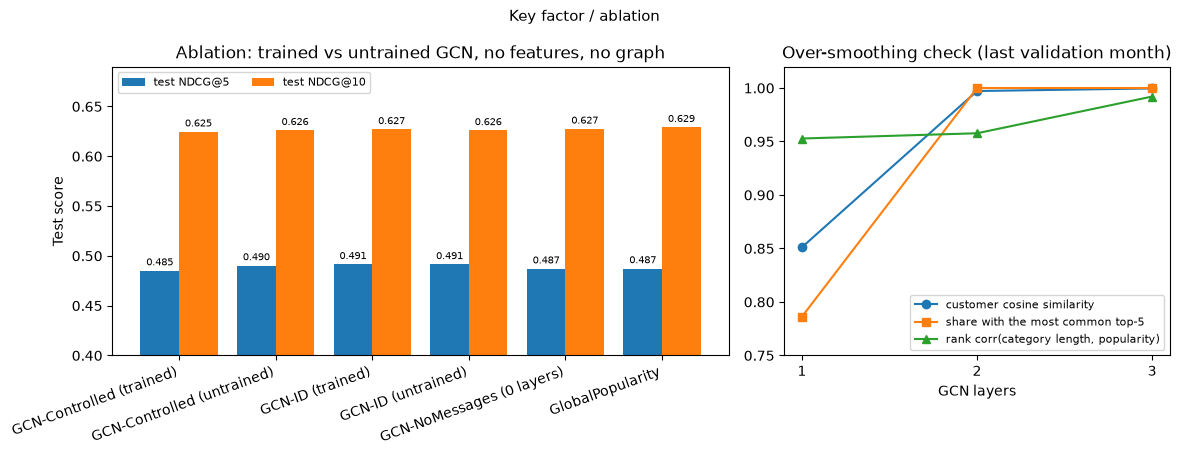

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
x = np.arange(len(ablation))
for offset, metric, color in [(-0.2, "NDCG@5", "tab:blue"), (0.2, "NDCG@10", "tab:orange")]:
    bars = ax.bar(x + offset, ablation[metric], width=0.4, color=color, label=f"test {metric}")
    for bar, value in zip(bars, ablation[metric]):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.003, f"{value:.3f}", ha="center", va="bottom", fontsize=7)
ax.set_xticks(x, ablation["model"], rotation=20, ha="right")
ax.set_ylim(0.40, 0.69)
ax.set_ylabel("Test score")
ax.legend(fontsize=8, loc="upper left", ncol=2)
ax.set_title("Ablation: trained vs untrained GCN, no features, no graph")
ax = axes[1]
for column, marker in [("customer cosine similarity", "o"), ("share with the most common top-5", "s"),
                       ("rank corr(category length, popularity)", "^")]:
    ax.plot(oversmoothing["layers"], oversmoothing[column], marker=marker, label=column)
ax.set_xticks([1, 2, 3])
ax.set_xlabel("GCN layers")
ax.set_ylim(0.75, 1.02)
ax.legend(fontsize=8, loc="lower right")
ax.set_title("Over-smoothing check (last validation month)")
fig.suptitle("Key factor / ablation", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "fig3_ablation.png", dpi=160, bbox_inches="tight")
plt.show()

**Result:** an untrained GCN already ranks like popularity. With random weights, GCN-Controlled scores test NDCG@5 0.490 / NDCG@10 0.626, slightly *higher* than after training (0.485 / 0.625), and an untrained GCN-ID (random IDs, no features) scores 0.491 / 0.626. With symmetric normalisation a category adds up the messages of its d buyers, each scaled by 1/√(d·d_u), so its vector length grows roughly with √d: the category vector lengths of the untrained models rank with popularity at 0.99. The random-ID control shows that this popularity-like ranking can arise without observed node features. This supports a degree-bias explanation; the square-root relation is an intuition, not an exact law for these learned vectors. Removing the message passing (GCN-NoMessages: 0.487 / 0.627) or the node features (GCN-ID) does not hurt; both are slightly higher than GCN-Controlled.

**Over-smoothing (right panel):** customer vectors have an average cosine similarity of 0.85 after 1 layer, 0.997 after 2 and 1.000 after 3. With 1 layer 79% of the customers get the month's most common top-5 category set; from 2 layers on it is 100%.

## 12. Success vs failure: where does the GCN do well or badly? — Figure 4

We use the GCN variant with the better **validation** NDCG@10 (not test) and look at the test months in two ways:
1. **Customer history:** four equal-size groups of test customer-months by how many categories the customer bought before (history degree), compared with GlobalPopularity.
2. **Repeat vs new categories:** of the categories bought in the test month, was it bought before ("repeat") or not ("new")? Recall@5 for each type.
3. **Which categories:** the most common top-5 list of the GCN in each test month (per seed) compared with the popularity top 5.

In [17]:
# MAIN was frozen using validation scores before test snapshots were loaded.
print("Variant used below:", MAIN)

snaps = DATA["test"]
gcn = pd.concat([instance_table(snaps, test_scores[MAIN, seed]) for seed in SEEDS])
gcn = gcn.groupby(["target_month", "customer_idx", "history_degree"], as_index=False)[METRICS[:-1]].mean()
pop = instance_table(snaps, [popularity_scores(s) for s in snaps])
gcn["quartile"] = pd.qcut(gcn["history_degree"].rank(method="first"), 4,
                          labels=["Q1 (fewest)", "Q2", "Q3", "Q4 (most)"])
quartile_rows = []
for quartile, group in gcn.groupby("quartile", observed=True):
    pop_part = pop.merge(group[["target_month", "customer_idx"]], on=["target_month", "customer_idx"])
    quartile_rows.append({"quartile": quartile,
                          "categories bought before": f"{group['history_degree'].min()}-{group['history_degree'].max()}",
                          "customer-months": len(group), "GCN NDCG@5": group["NDCG@5"].mean(),
                          "Popularity NDCG@5": pop_part["NDCG@5"].mean()})
quartiles = pd.DataFrame(quartile_rows)
quartiles["GCN - Popularity"] = quartiles["GCN NDCG@5"] - quartiles["Popularity NDCG@5"]


def repeat_new_recall(snaps, scores, k=5):
    hits, totals = {"repeat": 0, "new": 0}, {"repeat": 0, "new": 0}
    for s, sc in zip(snaps, scores):
        labels = s["labels"].numpy().astype(bool)
        top = np.zeros_like(labels)
        np.put_along_axis(top, np.argsort(-sc, axis=1, kind="stable")[:, :k], True, axis=1)
        for kind, mask in [("repeat", s["history_pair"]), ("new", ~s["history_pair"])]:
            hits[kind] += int((top & labels & mask).sum())
            totals[kind] += int((labels & mask).sum())
    return {f"{kind} Recall@{k}": hits[kind] / totals[kind] for kind in totals} | \
           {"repeat share of purchases": totals["repeat"] / (totals["repeat"] + totals["new"])}


repeat_new = pd.DataFrame(
    [{"method": f"GCN ({MAIN})", **pd.DataFrame([repeat_new_recall(snaps, test_scores[MAIN, seed]) for seed in SEEDS]).mean(),
      "share with the most common top-5": np.mean([same_top5_for_everyone(test_scores[MAIN, seed]) for seed in SEEDS])},
     {"method": "GlobalPopularity", **repeat_new_recall(snaps, [popularity_scores(s) for s in snaps]),
      "share with the most common top-5": 1.0}])
def most_common_top5(scores):
    return pd.Series([frozenset(r) for r in np.argsort(-scores, axis=1, kind="stable")[:, :5]]).value_counts().index[0]


top5_rows = []
for seed in SEEDS:
    for s, sc in zip(snaps, test_scores[MAIN, seed]):
        gcn_top, pop_top = most_common_top5(sc), most_common_top5(popularity_scores(s))
        top5_rows.append({"seed": seed, "month": s["month"], "same categories": len(gcn_top & pop_top),
                          "GCN only": ", ".join(CATEGORIES[i] for i in sorted(gcn_top - pop_top)),
                          "popularity only": ", ".join(CATEGORIES[i] for i in sorted(pop_top - gcn_top))})
display(quartiles.round(4))
display(repeat_new.round(4))
pd.DataFrame(top5_rows)

Variant used below: GCN-Tuned


,quartile,categories bought before,customer-months,GCN NDCG@5,Popularity NDCG@5,GCN - Popularity
0,Q1 (fewest),2-8,66,0.4828,0.4762,0.0066
1,Q2,8-10,65,0.4868,0.4952,-0.0084
2,Q3,10-12,65,0.5030,0.5109,-0.0079
3,Q4 (most),12-16,66,0.4787,0.4672,0.0114


,method,repeat Recall@5,new Recall@5,repeat share of purchases,share with the most common top-5
0,GCN (GCN-Tuned),0.5214,0.2716,0.6358,1.0
1,GlobalPopularity,0.5235,0.2629,0.6358,1.0


,seed,month,same categories,GCN only,popularity only
0,42,2024-11,4,Dairy & Eggs,Beverages
1,42,2024-12,4,Dairy & Eggs,Beverages
2,43,2024-11,4,Dairy & Eggs,Beverages
3,43,2024-12,4,Dairy & Eggs,Beverages
4,44,2024-11,4,Dairy & Eggs,Beverages
5,44,2024-12,4,Snacks,Beverages


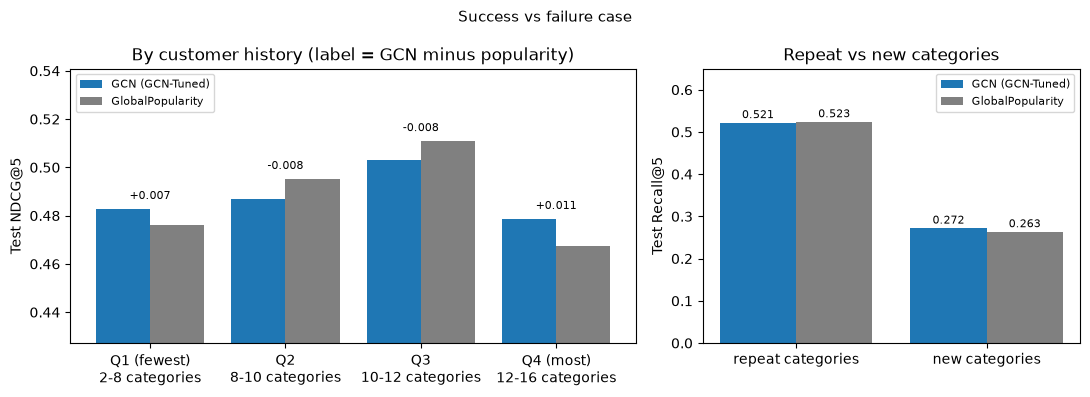

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
x = np.arange(len(quartiles))
ax.bar(x - 0.2, quartiles["GCN NDCG@5"], width=0.4, label=f"GCN ({MAIN})", color="tab:blue")
ax.bar(x + 0.2, quartiles["Popularity NDCG@5"], width=0.4, label="GlobalPopularity", color="grey")
for i, row in quartiles.iterrows():
    ax.text(i, max(row["GCN NDCG@5"], row["Popularity NDCG@5"]) + 0.003, f"{row['GCN - Popularity']:+.3f}",
            ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, [f"{q}\n{r} categories" for q, r in zip(quartiles["quartile"], quartiles["categories bought before"])])
ax.set_ylim(min(quartiles["GCN NDCG@5"].min(), quartiles["Popularity NDCG@5"].min()) - 0.04,
            max(quartiles["GCN NDCG@5"].max(), quartiles["Popularity NDCG@5"].max()) + 0.03)
ax.set_ylabel("Test NDCG@5")
ax.legend(fontsize=8, loc="upper left")
ax.set_title("By customer history (label = GCN minus popularity)")
ax = axes[1]
x = np.arange(2)
for offset, (_, row), color in zip([-0.2, 0.2], repeat_new.iterrows(), ["tab:blue", "grey"]):
    bars = ax.bar(x + offset, [row["repeat Recall@5"], row["new Recall@5"]], width=0.4, label=row["method"], color=color)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005, f"{bar.get_height():.3f}",
                ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, ["repeat categories", "new categories"])
ax.set_ylabel("Test Recall@5")
ax.set_ylim(0, 0.65)
ax.legend(fontsize=8)
ax.set_title("Repeat vs new categories")
fig.suptitle("Success vs failure case", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "fig4_success_failure.png", dpi=160, bbox_inches="tight")
plt.show()

**Result:** GCN-Tuned is slightly above popularity for the shortest-history group (NDCG@5 0.4828 vs 0.4762) and longest-history group (0.4787 vs 0.4672), and about 0.008 below it for the middle groups. These are descriptive differences; there is no subgroup significance test. Quartiles have equal counts, so tied history degrees can straddle adjacent groups.

Within each test month and seed, every customer receives the same **set** of top-5 categories; order may differ. The set shares four categories with popularity (Grains & Staples, Fruits & Vegetables, Bakery, Household). The GCN includes Dairy & Eggs, or Snacks in one seed-month, instead of Beverages. Repeat-category Recall@5 is 0.5214 vs 0.5235 for popularity; new-category Recall@5 is 0.2716 vs 0.2629. These repeat/new recalls pool relevant purchases, unlike the main macro customer-month metrics. The results suggest limited personalisation of top-5 membership.

## 13. Compared with Dataset 1 (EuroMart) — Figure 5

The EuroMart GCN is reported by Yi Xuan in `GCN_DS1_EuroMart.ipynb` (report Section 3.4.2; quarterly split, as in the final standard). To explain why the two datasets behave differently we compare their **structure**, using the shared processed transactions and the same definitions as Run 2, but each dataset in its own standard time unit: EuroMart **quarters** (test 2014Q2–Q4), Retail POS **months** (test Nov–Dec 2024).
- *Graph density*: customer–category pairs ever bought / (customers × 17), over the whole history.
- *Categories per customer*: mean number of the 17 categories a customer has ever bought.
- *Positive rate*: in each test period, bought pairs / (eligible customers × 17); eligible = seen before and active in the period.
- *Repeat share*: of the pairs bought in a test period, the share that the customer had bought before.

The Retail POS numbers are checked against the Run 2 snapshot index.

In [19]:
def structure(df, period, test_periods):
    pairs_all = df[["customer_id", "category"]].drop_duplicates()
    n_customers = df["customer_id"].nunique()
    eligible = positives = repeats = 0
    for p in test_periods:
        history, target = df[df[period] < p], df[df[period] == p]
        target = target[target["customer_id"].isin(set(history["customer_id"]))]
        bought = target[["customer_id", "category"]].drop_duplicates()
        before = set(map(tuple, history[["customer_id", "category"]].drop_duplicates().to_numpy()))
        eligible += target["customer_id"].nunique()
        positives += len(bought)
        repeats += sum((c, k) in before for c, k in bought.to_numpy())
    return {"customers": n_customers, "graph density": len(pairs_all) / (n_customers * N_CAT),
            "categories per customer": len(pairs_all) / n_customers,
            "test eligible customer-periods": eligible, "test positive rate": positives / (eligible * N_CAT),
            "test repeat share": repeats / positives, "_positives": positives, "_repeats": repeats}


tx = {name: pd.read_csv(ROOT / f"data/v3/processed/{name}_transactions_v3.csv", dtype={"customer_id": str})
      for name in ["euromart", "retail_pos"]}
tx["euromart"]["quarter"] = pd.PeriodIndex(pd.to_datetime(tx["euromart"]["event_time"]), freq="Q").astype(str)
compare = pd.DataFrame({
    "EuroMart (quarterly)": structure(tx["euromart"], "quarter", ["2014Q2", "2014Q3", "2014Q4"]),
    "Retail POS (monthly)": structure(tx["retail_pos"], "month", ["2024-11", "2024-12"])})

run2 = INDEX[INDEX["split"].eq("test")]                    # check the Retail POS numbers against Run 2
assert compare.loc["test eligible customer-periods", "Retail POS (monthly)"] == run2["eligible_customers"].sum()
assert compare.loc["_positives", "Retail POS (monthly)"] == run2["positive_pairs"].sum()
assert compare.loc["_repeats", "Retail POS (monthly)"] == run2["repeated_positive_pairs"].sum()
print("Retail POS counts match the Run 2 snapshot index.")
compare = compare.drop(["_positives", "_repeats"])
compare.round(3)

Retail POS counts match the Run 2 snapshot index.


,EuroMart (quarterly),Retail POS (monthly)
customers,792.000,488.000
graph density,0.400,0.613
categories per customer,6.799,10.418
test eligible customer-periods,872.000,262.000
test positive rate,0.129,0.286
test repeat share,0.430,0.636


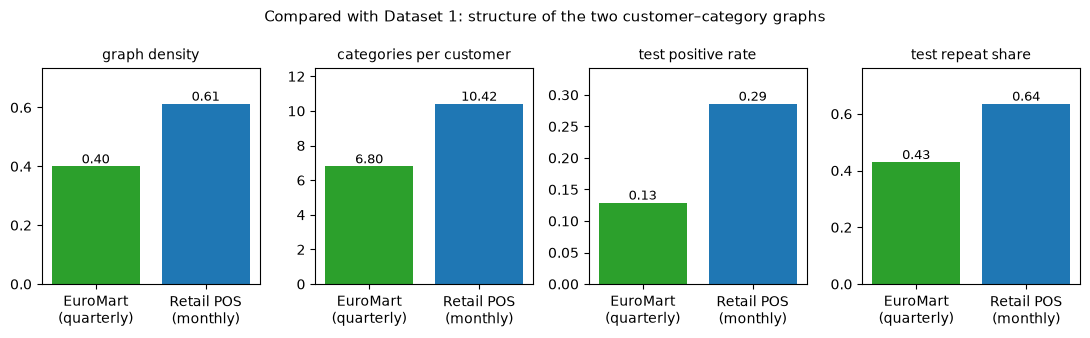

In [20]:
PANELS = ["graph density", "categories per customer", "test positive rate", "test repeat share"]
fig, axes = plt.subplots(1, len(PANELS), figsize=(11, 3.4))
for ax, row in zip(axes, PANELS):
    values = compare.loc[row].astype(float)
    bars = ax.bar(["EuroMart\n(quarterly)", "Retail POS\n(monthly)"], values, color=["tab:green", "tab:blue"])
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(row, fontsize=10)
    ax.set_ylim(0, values.max() * 1.2)
fig.suptitle("Compared with Dataset 1: structure of the two customer–category graphs", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "fig5_dataset_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

**Result:** the descriptive all-history customer–category graph is denser for Retail POS (61% of possible pairs; 10.4 categories per customer) than EuroMart (40%; 6.8). Test positive and repeat rates also differ (Retail POS: 29% and 64%; EuroMart: 13% and 43%). The density is calculated over all transactions, including test-period transactions, and is not the graph used for training or prediction. A densely shared category graph is consistent with the observed customer-vector similarity, but density alone does not prove its cause.

These figures describe the data only. EuroMart uses quarterly targets while Retail POS uses monthly targets, so absolute prediction scores are not directly comparable. Yi Xuan owns the EuroMart GCN and its final-standard rerun; no EuroMart model results are copied into Hansen's evaluation.

## 14. Precision–recall curves on the test months — Figure 6

PR-AUC (Section 5) pools every test customer-month × category pair and ranks them by score. The curve shows precision against recall at each score threshold for the reporting variant, one line per final seed; equal scores share one threshold, exactly as in `average_precision`. The dashed line is the share of pairs that were bought, which is what a random ranking would reach.

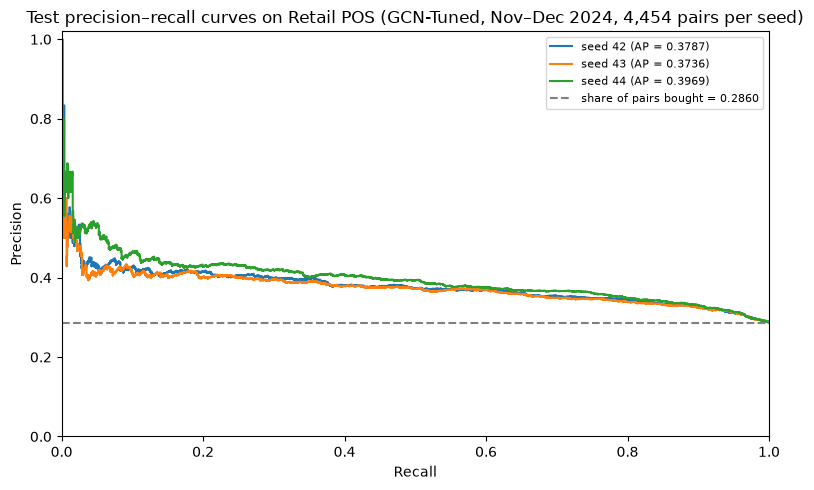

GCN-Tuned test PR-AUC 0.3831 ± 0.0123 (mean ± sample SD over seeds); GlobalPopularity 0.4148


In [21]:
def precision_recall_curve(labels, scores):
    """Recall and precision at every distinct score threshold (equal scores share one threshold)."""
    y, s = np.ravel(labels).astype(float), np.ravel(scores).astype(float)
    order = np.argsort(-s, kind="mergesort")
    y, s = y[order], s[order]
    last_of_each_score = np.r_[np.flatnonzero(np.diff(s)), len(s) - 1]
    true_pos = np.cumsum(y)[last_of_each_score]
    return true_pos / true_pos[-1], true_pos / (last_of_each_score + 1)


fig, ax = plt.subplots(figsize=(8, 5))
pr_points = []
for seed, color in zip(SEEDS, ["tab:blue", "tab:orange", "tab:green"]):
    recall, precision = precision_recall_curve(test_labels, np.concatenate(test_scores[MAIN, seed]))
    ap = results.query("split == 'test' and variant == @MAIN and seed == @seed")["PR-AUC"].item()
    assert np.isclose(np.sum(np.diff(np.r_[0.0, recall]) * precision), ap, rtol=0, atol=1e-12)   # area = PR-AUC
    recall, precision = np.r_[0.0, recall], np.r_[1.0, precision]
    ax.step(recall, precision, where="pre", color=color, label=f"seed {seed} (AP = {ap:.4f})")
    pr_points.append(pd.DataFrame({"seed": seed, "recall": recall, "precision": precision}))
pr_points = pd.concat(pr_points, ignore_index=True)
ax.axhline(test_labels.mean(), color="grey", linestyle="--", label=f"share of pairs bought = {test_labels.mean():.4f}")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Recall", ylabel="Precision")
ax.legend(fontsize=8, loc="upper right")
ax.set_title(f"Test precision–recall curves on Retail POS ({MAIN}, Nov–Dec 2024, {test_labels.size:,} pairs per seed)")
plt.tight_layout()
plt.savefig(FIG / "fig6_precision_recall_curve.png", dpi=160, bbox_inches="tight")
plt.show()

ap = results.query("split == 'test' and variant == @MAIN")["PR-AUC"]
print(f"{MAIN} test PR-AUC {ap.mean():.4f} ± {ap.std():.4f} (mean ± sample SD over seeds); "
      f"GlobalPopularity {shared.loc[('GlobalPopularity', 'test'), ('PR-AUC', 'mean')]:.4f}")

**Result:** precision falls as recall rises. The curves only move sharply at the very start (recall below about 0.05), where precision rests on a few top-scored pairs; after that they decline smoothly towards the 0.286 share of bought pairs. The three seeds give AP 0.3787, 0.3736 and 0.3969 (0.3831 ± 0.0123, mean ± sample SD), below GlobalPopularity's 0.4148 (Section 10).

## 15. Save results in the team's standard format

- `results_hansen.csv`: one row per variant / seed / split with the contract's result columns (+ training seconds)
- `configs_hansen.json`: frozen settings (saved in Section 9 before testing)
- `tables/`: tuning log, mean ± SD summary, comparison with baselines, ablation, over-smoothing, quartiles, repeat-vs-new, dataset comparison
- `training_history_hansen.csv`: loss and validation NDCG@10 per epoch for every final run
- `predictions/predictions_hansen_retail_pos_<variant>_seed<seed>.csv.gz`: test scores for every customer-month-category
- `tables/gcn_precision_recall_test.csv`: the precision–recall curve points of Figure 6
- Figures 1–6 in `results/v4/run4_gcn/figures/`

In [22]:
standard = results.assign(contract_version="3.0", dataset=DATASET, method="GCN", owner="Hansen",
                          comparison_track=results["variant"].map({"GCN-ID": "id_control", "GCN-NoMessages": "ablation"})
                          .fillna("feature_aware"))
standard[CONTRACT["result_columns"] + ["training_seconds"]].to_csv(OUT / "results_hansen.csv", index=False)

summary = results.groupby(["variant", "split"], sort=False)[METRICS].agg(["mean", "std"])
summary.columns = [f"{m}_{'sd' if a == 'std' else a}" for m, a in summary.columns]
summary.reset_index().to_csv(OUT / "tables" / "gcn_summary_mean_sd.csv", index=False)
try:
    git_head = subprocess.check_output(["git", "rev-parse", "HEAD"], text=True, stderr=subprocess.DEVNULL).strip()
except (OSError, subprocess.CalledProcessError):
    git_head = None                                     # not run from a git checkout
# Provenance: the workbook is git-ignored; its checksum records the reviewed version.
manifest = {
    "run_utc": datetime.now(timezone.utc).isoformat(),
    "git_head": git_head,
    "dataset": DATASET, "owner": "Hansen", "selection_metric": SELECT, "headline_metric": HEADLINE,
    "source_standard_sha256": "0cceca5ad5801fe79c3422e137f6b4b0153ea6d2a2855aae8f3f90d8f6b1065a",
    "standard_checked_date": "2026-10-13", "seeds": SEEDS, "pos_weight": POS_WEIGHT,
    "search_budget": SEARCH_BUDGET, "final_budget": FINAL_BUDGET, "reporting_variant": MAIN,
    "python": platform.python_version(), "torch": torch.__version__, "numpy": np.__version__,
    "pandas": pd.__version__, "torch_threads": torch.get_num_threads(),
    "snapshots_sha256": {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                         for p in sorted((GRAPH_DIR / DATASET / "monthly").glob("*.npz"))},
    "notebook_source_sha256": hashlib.sha256("\n".join("".join(c["source"]) for c in
        json.loads((ROOT / "GCN_DS2_POS.ipynb").read_text(encoding="utf-8"))["cells"]).encode()).hexdigest(),
}
(OUT / "run_manifest_hansen.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
pd.DataFrame(top5_rows).to_csv(OUT / "tables" / "gcn_top5_categories_test.csv", index=False)
pr_points.to_csv(OUT / "tables" / "gcn_precision_recall_test.csv", index=False)
test_table.to_csv(OUT / "tables" / "gcn_vs_baselines_test.csv")
sensitivity.to_csv(OUT / "tables" / "gcn_sensitivity_validation.csv", index=False)
ablation.to_csv(OUT / "tables" / "gcn_ablation_test.csv", index=False)
oversmoothing.to_csv(OUT / "tables" / "gcn_oversmoothing.csv", index=False)
quartiles.to_csv(OUT / "tables" / "gcn_history_quartiles_test.csv", index=False)
repeat_new.to_csv(OUT / "tables" / "gcn_repeat_vs_new_test.csv", index=False)
compare.to_csv(OUT / "tables" / "dataset_structure_comparison.csv")
pd.concat(histories, ignore_index=True).to_csv(OUT / "training_history_hansen.csv", index=False)
for (variant, seed), scores in test_scores.items():
    prediction_table(DATA["test"], scores).to_csv(
        OUT / "predictions" / f"predictions_hansen_{DATASET}_{variant}_seed{seed}.csv.gz", index=False)
print("Saved", len(standard), "result rows and", len(test_scores), "prediction files to", OUT.relative_to(ROOT))

Saved 36 result rows and 12 prediction files to results\v4\run4_gcn


## 16. Conclusions

1. **Final standard verified:** Run 2 Retail POS monthly snapshots (8 / 2 / 2 months), 17 categories, 7 + 7 features, full weighted BCE, validation NDCG@10 selection, seeds 42 / 43 / 44, dot-product decoder and all 13 required metrics.
2. **Depth:** 2 layers is best on validation (NDCG@10 0.6303), only 0.0016 above the zero-layer reference. From 2 layers, top-5 category membership is identical across validation customers.
3. **Tuning:** only weight decay 1e-4 was retained (+0.0022 validation NDCG@10). The search varies one setting at a time rather than all combinations.
4. **Test:** GCN-Tuned reaches NDCG@5 0.4877 and NDCG@10 0.6262, versus 0.4870 / 0.6274 without the GCN stack and 0.4873 / 0.6291 for popularity. The tested GCN does not show a consistent advantage over these references.
5. **Interpretation:** popularity-like untrained rankings, category-vector length correlation near 0.99 and customer cosine similarity near 1 support degree bias and over-smoothing as explanations for limited personalised top-5 membership.

*Limits:* only three seeds, two validation months and two test months; no significance or equivalence test was performed. The zero-layer ablation also removes trainable transforms, so it does not isolate adjacency propagation from model capacity. Final ReLU makes dot-product logits non-negative (sigmoid scores at least 0.5), which limits probability calibration; PR-AUC evaluates ranking, not calibration. EuroMart model evaluation belongs to Yi Xuan.
